# Wasserstein GAN to generate steel samples 

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np
from keras.layers import Dense
from keras.layers import Dropout
from keras.models import Sequential
import keras.src.saving
import xgboost as xgb
from keras.optimizers import RMSprop
from keras import backend
from keras.src.layers import LeakyReLU, BatchNormalization, Activation


<br>

## 1. Load and prepare data

In [3]:
# Read labeled_OES_data_2.csv
data = pd.read_csv("labeled_OES_data_2.csv")

# convert steel types to numbers
# Note: in our project steel types are not predefined, but will be extracted from the supplied file of data
classes_dict = {"St 48" : 0, "St 37" : 1, "St Si" : 2, "St 48-TH" : 3, "Puddelstahl" : 4}
data["steel_class"] = [classes_dict[c] for c in data["steel_class"] ]    

# make data numeric
for column in data.columns:
        for index, value in data[column].items():
            if isinstance(value, str):
                data.at[index, column] = value.replace(",", ".")
data = data.map(pd.to_numeric)
data.iloc[12]

C              0.076
Si             0.005
Mn             0.402
P              0.017
S              0.018
Cr             0.044
Ni             0.036
Al             0.002
Cu             0.091
steel_class    1.000
Name: 12, dtype: float64

## 2. Group dataset by steel types

In [4]:
element_data_grouped_by_steeltype = data.groupby("steel_class")
dfs_by_steeltype = {}

for type, group_data in element_data_grouped_by_steeltype:
    dfs_by_steeltype[type] = group_data.iloc[:, :-1]

for type in dfs_by_steeltype.keys():
    print(f"\nSteel Type {type}:")
    print(dfs_by_steeltype[type].head())


Steel Type 0:
       C     Si     Mn      P      S     Cr     Ni     Al     Cu
1  0.262  0.219  0.525  0.021  0.040  0.035  0.051  0.002  0.145
2  0.235  0.239  0.729  0.028  0.042  0.015  0.050  0.004  0.167
4  0.195  0.321  0.570  0.033  0.057  0.023  0.075  0.007  0.281
5  0.130  0.438  0.691  0.020  0.037  0.020  0.044  0.004  0.437
7  0.284  0.233  0.635  0.022  0.042  0.009  0.050  0.003  0.175

Steel Type 1:
        C     Si     Mn      P      S     Cr     Ni     Al     Cu
12  0.076  0.005  0.402  0.017  0.018  0.044  0.036  0.002  0.091
17  0.070  0.005  0.428  0.008  0.018  0.005  0.027  0.002  0.098
33  0.069  0.005  0.392  0.020  0.028  0.008  0.035  0.002  0.122
36  0.058  0.005  0.393  0.029  0.030  0.022  0.052  0.002  0.172
37  0.061  0.005  0.312  0.020  0.035  0.025  0.047  0.002  0.147

Steel Type 2:
        C     Si     Mn      P      S     Cr     Ni     Al     Cu
0   0.104  0.806  0.890  0.031  0.044  0.013  0.047  0.006  0.168
3   0.116  0.848  0.737  0.023  0.038

### Get element distribution of St 48-TH

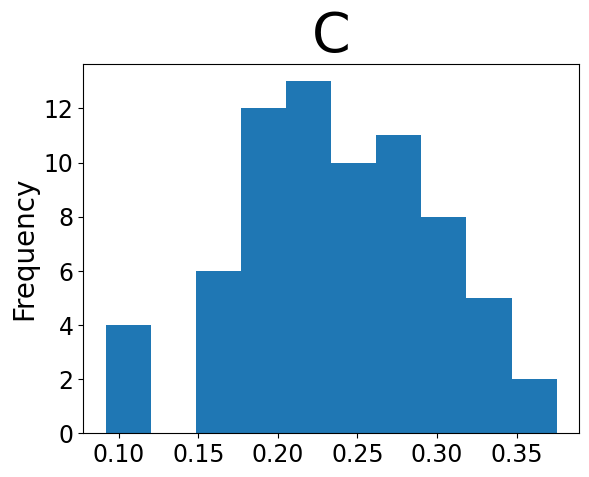

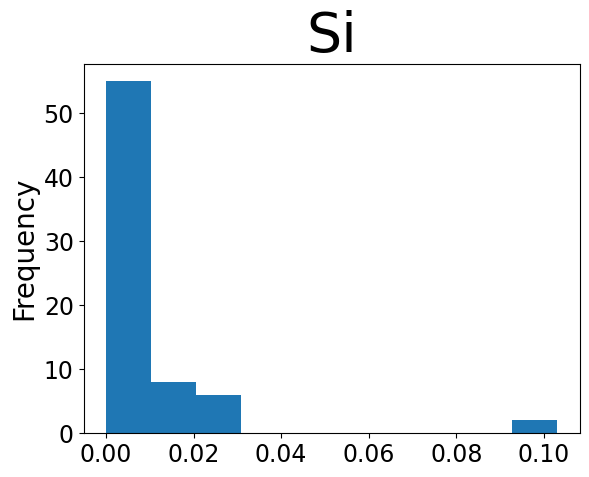

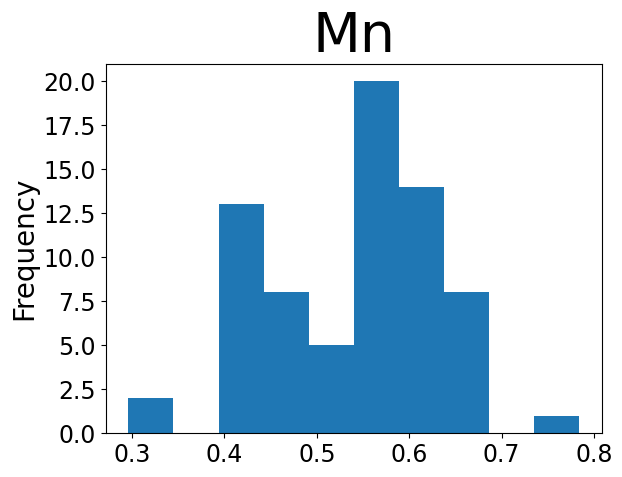

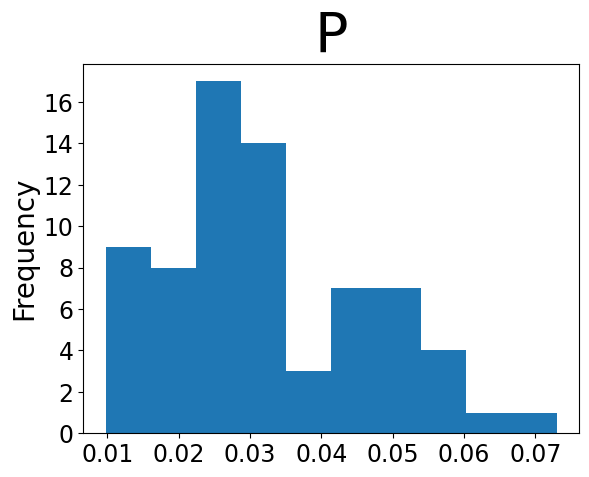

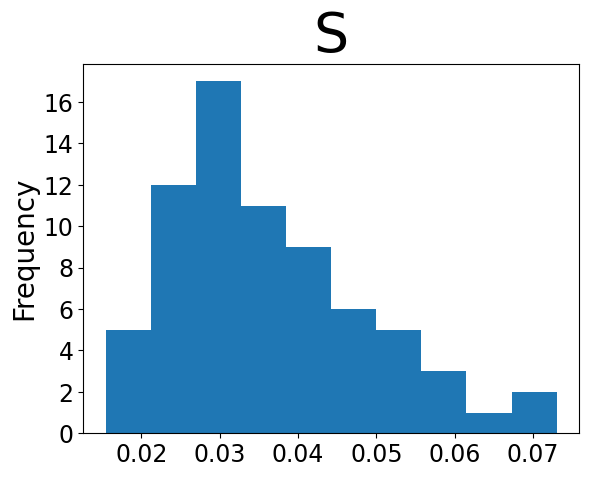

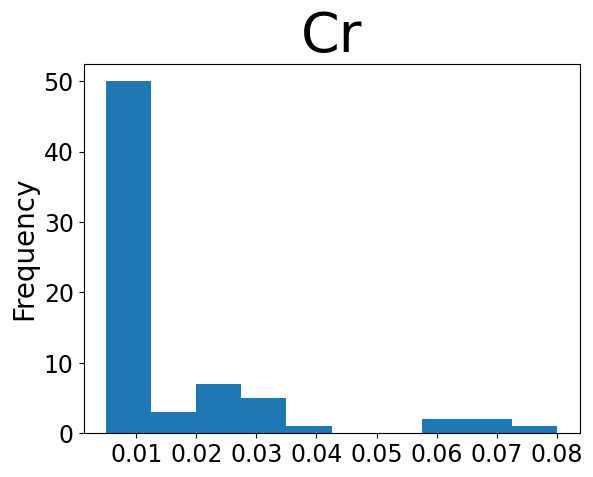

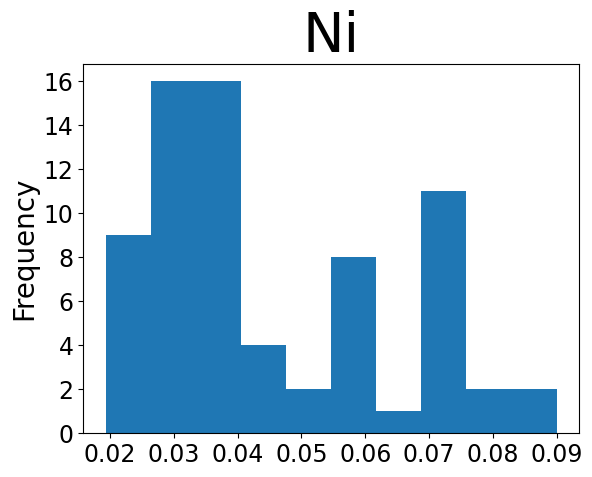

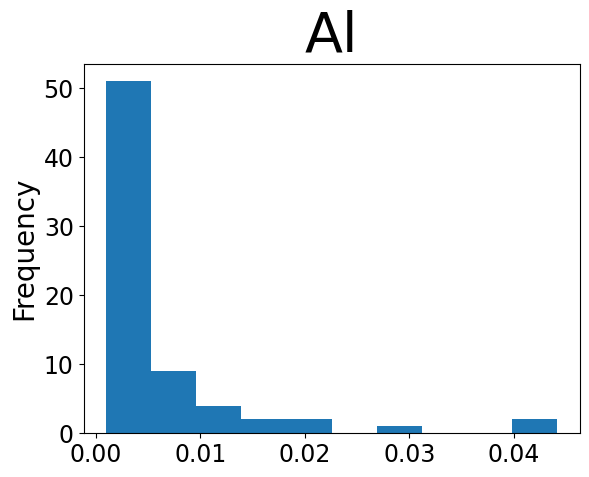

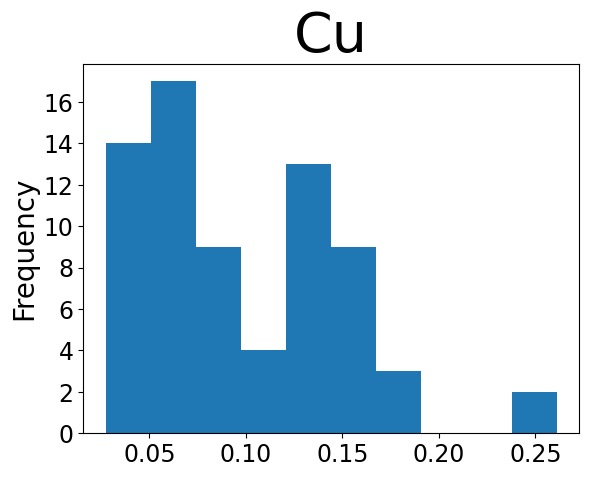

In [28]:
for col in dfs_by_steeltype[3].columns:  # Loop through columns (excluding the first)
    dfs_by_steeltype[3][col].plot.hist()
    plt.title(col, fontsize=40)  # Set title as element name
    plt.ylabel("Frequency", fontsize=20)
    plt.xticks(fontsize=17)  # Adjust x-axis tick label font size
    plt.yticks(fontsize=17)
    #plt.savefig(f"St48_TH_Distribution_{col}.png", format='png')
    plt.show()
    plt.close()


<br>

## 3. Create construct for WGAN

In [4]:
# latent space is random noise out of which the data will be formed
def build_generator(latent_space):
    generator = Sequential()
    generator.add(Dense(latent_space, input_dim=latent_space))
    generator.add(LeakyReLU(alpha=0.2))
    generator.add(BatchNormalization(momentum=0.8))
    generator.add(Dense(256))
    generator.add(LeakyReLU(alpha=0.2))
    generator.add(BatchNormalization(momentum=0.8))
    generator.add(Dense(512))
    generator.add(LeakyReLU(alpha=0.2))
    generator.add(BatchNormalization(momentum=0.8))
    generator.add(Dense(9))
    generator.add(Activation('sigmoid'))
    return generator

In [5]:
def build_critic():
    critic = Sequential()
    critic.add(Dense(9, input_dim=9))
    critic.add(Dense(512))
    critic.add(LeakyReLU(alpha=0.2))
    critic.add(Dropout(0.3))
    critic.add(Dense(256))
    critic.add(LeakyReLU(alpha=0.2))
    critic.add(Dropout(0.3))
    critic.add(Dense(128))
    critic.add(LeakyReLU(alpha=0.2))
    critic.add(Dense(1))
    return critic

In [6]:
def build_wgan(generator, critic):
    wgan = Sequential()
    wgan.add(generator)
    wgan.add(critic)
    return wgan

In [7]:

def weight_clipping(weights, weight_clipping_value):
    return backend.clip(weights, -weight_clipping_value, weight_clipping_value)

In [8]:
def wasserstein_loss_gen(fake_output):
    return -tf.reduce_mean(fake_output)

def wasserstein_loss_critic(real_output, fake_output):
    return -(tf.reduce_mean(real_output) - tf.reduce_mean(fake_output))

<br>

## 4. Create Generator, Discriminator and WGAN

In [7]:
latent_space = 20

In [10]:
optimizer_critic = RMSprop(learning_rate=0.0005)
optimizer_wgan = RMSprop(learning_rate=0.0005)

critic_St48_TH = build_critic()
critic_St48_TH.compile(optimizer=optimizer_critic, loss=wasserstein_loss_critic)

generator_St48_TH = build_generator(latent_space)
generator_St48_TH.summary()

wgan_St48_TH = build_wgan(generator_St48_TH, critic_St48_TH)
wgan_St48_TH.compile(optimizer=optimizer_wgan, loss=wasserstein_loss_gen)

C:\Users\jonat\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
C:\Users\jonat\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\activations\leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                      │ (None, 20)                  │             420 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_3 (LeakyReLU)            │ (None, 20)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 20)                  │              80 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 256)                 │           5,376 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_4 (LeakyReLU)            │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 512)                 │         131,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_5 (LeakyReLU)            │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 512)                 │           2,048 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 9)                   │           4,617 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation (Activation)              │ (None, 9)                   │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 145,149 (566.99 KB)

 Trainable params: 143,573 (560.83 KB)

 Non-trainable params: 1,576 (6.16 KB)

In [11]:
critic_St48_TH.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 9)                   │              90 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 512)                 │           5,120 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu (LeakyReLU)              │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_1 (LeakyReLU)            │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_2 (LeakyReLU)            │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 169,563 (662.36 KB)

 Trainable params: 169,563 (662.36 KB)

 Non-trainable params: 0 (0.00 B)

<br>

## 5. Train the GAN

**To make the first training more ressource friendly we chose a low number of epochs and a low batch size**

In [8]:
epochs = 2500
batch_size = 64 
weight_clipping_value = 0.01
iteration_critic = 5
X_train_St48_TH = dfs_by_steeltype[3]


In [ ]:
c_real_hist = []
c_fake_hist = []
wgan_hist = []

for epoch in range(epochs):
    c_real_iteration = []
    c_fake_iteration = []
    for iteration in range(iteration_critic):
        
        real_samples = X_train_St48_TH.values[np.random.randint(0, X_train_St48_TH.shape[0], batch_size)]
        
        lat_noise = np.random.normal(0, 1, (batch_size, latent_space))
        fakes = generator_St48_TH.predict(lat_noise)

         # Train the critic
        with tf.GradientTape() as tape:
            real_output = critic_St48_TH(real_samples, training=True)
            fake_output = critic_St48_TH(fakes, training=True)
            c_loss = wasserstein_loss_critic(real_output, fake_output)
        gradients = tape.gradient(c_loss, critic_St48_TH.trainable_variables)
        optimizer_critic.apply_gradients(zip(gradients, critic_St48_TH.trainable_variables))

        for layer in critic_St48_TH.layers:
                weights = layer.get_weights()
                weights = [np.clip(w, -weight_clipping_value, weight_clipping_value) for w in weights]
                layer.set_weights(weights)
    
    lat_noise = np.random.normal(0, 1, (batch_size, latent_space))

    with tf.GradientTape() as tape:
        generated_data = generator_St48_TH(lat_noise, training=True)
        fake_output = critic_St48_TH(generated_data, training=False)
        g_loss = wasserstein_loss_gen(fake_output)
    gradients = tape.gradient(g_loss, generator_St48_TH.trainable_variables)
    optimizer_wgan.apply_gradients(zip(gradients, generator_St48_TH.trainable_variables))

    print(f'Epoch: {epoch+1}, Critic Loss: {c_loss.numpy()}, Generator Loss: {g_loss.numpy()}')
    wgan_hist.append(g_loss)
    c_real_hist.append(c_loss)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step  
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Epoch: 1, Critic Loss: 2.2543754312209785e-06, Generator Loss: 8.408799476455897e-05
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Epoch: 2, Critic Loss: -1.95114262169227e-06, Generator Loss: 6.986108201090246e-05
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Epoch: 3, Critic Loss: -1.50687264977023e-06, Generator Loss: 7.184599962783977e-05
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━

In [ ]:
plt.plot(c_real_hist, label='critic loss')
plt.plot(wgan_hist, label='gen loss')
plt.legend()
#plt.savefig('WGAN_loss_fig.png')
plt.show()

In [ ]:
#Save the generator model
#generator_St48_TH.save("WGAN_generator_St48_TH_1000Epochs.keras")

# Save the discriminator model
#critic_St48_TH.save("critic_St48_TH_1000Epochs.keras")


<br>

## 6. Augment new data with the generator

<br>

In [14]:
!pip show keras
!pip show tensorflow

Name: keras
Version: 3.2.1
Summary: Multi-backend Keras.
Home-page: https://github.com/keras-team/keras
Author: Keras team
Author-email: keras-users@googlegroups.com
License: Apache License 2.0
Location: C:\Users\jonat\AppData\Local\Programs\Python\Python312\Lib\site-packages
Requires: absl-py, h5py, ml-dtypes, namex, numpy, optree, rich
Required-by: tensorflow-intel
Name: tensorflow
Version: 2.16.1
Summary: TensorFlow is an open source machine learning framework for everyone.
Home-page: https://www.tensorflow.org/
Author: Google Inc.
Author-email: packages@tensorflow.org
License: Apache 2.0
Location: C:\Users\jonat\AppData\Local\Programs\Python\Python312\Lib\site-packages
Requires: tensorflow-intel
Required-by: 


In [32]:
import os.path
print(os.path.isfile("WGAN_generator_St48_TH_2500Epochs.keras"))

True


In [5]:
generator_St48_TH = keras.models.load_model("WGAN_generator_St48_TH_2500Epochs.keras", safe_mode=False)

In [8]:
lat_noise = np.random.normal(0, 1, (100, latent_space))
augmented_data_St48_TH = generator_St48_TH.predict(lat_noise)

augmented_data_St48_TH

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


array([[3.62183183e-01, 1.05753783e-02, 3.38101119e-01, 2.97616925e-02,
        1.21234760e-01, 1.42455157e-02, 7.38336295e-02, 7.28547946e-03,
        8.84263739e-02],
       [2.70890921e-01, 3.41165485e-03, 6.78494930e-01, 4.34802286e-02,
        4.15678658e-02, 5.45852073e-03, 5.16164005e-02, 3.46507598e-03,
        9.74489674e-02],
       [2.94895649e-01, 2.28120922e-03, 2.90818125e-01, 7.79713364e-03,
        1.23593025e-02, 3.34426039e-03, 8.12871829e-02, 1.36026344e-03,
        1.14366107e-01],
       [2.66725332e-01, 8.72023776e-03, 6.41082585e-01, 1.86109021e-02,
        2.65256036e-02, 2.00349744e-02, 1.28650488e-02, 1.03330975e-02,
        2.89056674e-02],
       [2.90024072e-01, 2.81404592e-02, 4.73891109e-01, 4.60857302e-02,
        5.15011288e-02, 1.92682054e-02, 4.21213433e-02, 1.18731316e-02,
        4.17814776e-02],
       [3.12755913e-01, 4.30449378e-03, 3.65575969e-01, 3.11305746e-03,
        3.24628712e-03, 6.62805745e-03, 1.16238697e-02, 1.74198172e-03,
        1.4

<br>

**Compare augmented data to real ones after PCA on a 3D coordinate system**

In [35]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from matplotlib.lines import Line2D

In [36]:
scaler = StandardScaler()
scaled_augmented_rows = scaler.fit_transform(augmented_data_St48_TH)
scaled_augmented_rows

array([[-7.78731823e-01,  2.97920793e-01, -2.68575341e-01,
         9.33769226e-01,  1.30254418e-01,  1.75938988e+00,
        -2.76992917e-02,  9.29247081e-01, -3.61247599e-01],
       [-1.29407370e+00,  7.92363226e-01, -1.75063944e+00,
        -3.65403026e-01, -3.59332651e-01, -3.10013264e-01,
         1.62323669e-01, -2.27234989e-01, -3.78320515e-01],
       [-6.04942620e-01, -4.01961952e-01,  1.76310882e-01,
        -7.22177207e-01, -1.58677056e-01, -4.90095526e-01,
        -3.67902726e-01, -4.44546521e-01, -1.78085998e-01],
       [-9.64236081e-01,  5.40114760e-01,  1.08052719e+00,
        -2.56905824e-01,  1.58703014e-01,  2.05397218e-01,
        -4.92739648e-01,  2.63437867e-01, -4.95016664e-01],
       [-3.20073545e-01, -1.96665347e-01,  6.15153790e-01,
         1.09036386e+00, -3.02543640e-01,  3.49419042e-02,
        -2.48936296e-01, -4.57823038e-01, -4.87531722e-01],
       [ 1.03940094e+00,  9.55513343e-02, -7.04229712e-01,
         7.41801634e-02, -2.33448207e-01,  2.215860

In [37]:
pca = PCA(3)
pca_augmented_rows = pca.fit_transform(scaled_augmented_rows)
pca_augmented_rows 

array([[ 1.4754771e+00, -1.2239122e+00, -3.7922251e-01],
       [-9.5557548e-02, -1.9930151e+00,  5.9889942e-01],
       [-1.0656233e+00, -1.8080756e-01,  6.3417929e-01],
       [-1.1714318e-01, -5.1453519e-01,  5.0931293e-01],
       [-2.0438787e-01,  4.8794910e-02,  5.4304492e-02],
       [ 8.1116813e-01, -7.1018481e-01, -2.1246550e+00],
       [-1.8063499e-01,  1.0177618e+00,  2.0017461e-03],
       [-1.7612695e+00, -3.5282323e-01,  5.2486628e-01],
       [ 1.8022313e+00,  2.1329021e-01, -9.6776795e-01],
       [-3.6058471e-01,  3.2680288e-01, -4.9404666e-01],
       [-3.5244274e-01, -3.0111367e-01,  1.0302816e-01],
       [ 9.6095167e-02,  1.1721532e-01,  7.2399497e-01],
       [-3.2934222e-01, -3.8945162e-01,  7.2274452e-01],
       [ 4.7857746e-02, -6.1162364e-01, -5.3609622e-01],
       [ 5.5992108e-02, -1.2899305e+00,  3.0172640e-01],
       [-7.3956329e-01,  7.6484829e-01, -8.4070528e-01],
       [ 3.2990909e-01,  7.7934813e-01, -1.0195293e+00],
       [-7.5738811e-01,  1.7561

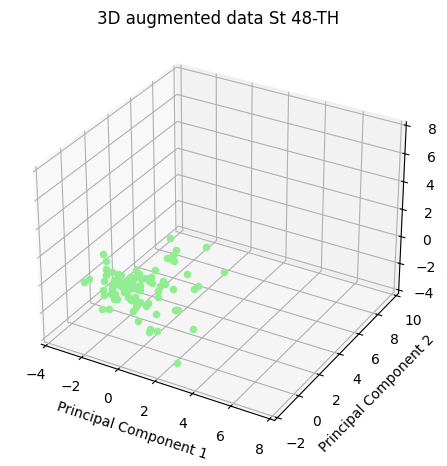

In [38]:
x = pca_augmented_rows[:, 0]
y = pca_augmented_rows[:, 1]
z = pca_augmented_rows[:, 2]

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

for i in range(len(x)):
        ax.scatter(x[i], y[i], z[i], c='lightgreen', marker='o')

ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_zlabel('Principal Component 3')
ax.set_title('3D augmented data St 48-TH')

ax.set_xlim(-4, 8)
ax.set_ylim(-2, 10)
ax.set_zlim(-4, 8)

#plt.savefig('Aug_St48_TH_WGAN.jpg', format='jpg')

plt.tight_layout()
plt.show()

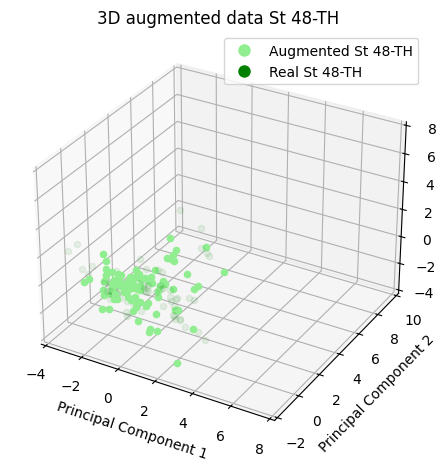

In [49]:
St48_TH_samples = dfs_by_steeltype[3]
scaled_St48_TH_rows = scaler.fit_transform(St48_TH_samples)
pca_St48_TH_rows = pca.fit_transform(scaled_St48_TH_rows)

x_St48_TH = pca_St48_TH_rows[:, 0]
y_St48_TH = pca_St48_TH_rows[:, 1]
z_St48_TH = pca_St48_TH_rows[:, 2]

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

for i in range(len(x)):
        ax.scatter(x[i], y[i], z[i], c='lightgreen', marker='o', label="Augmented St 48-TH")

for i in range(len(x_St48_TH)):
        ax.scatter(x_St48_TH[i], y_St48_TH[i], z_St48_TH[i], c='g', marker='o', alpha=0.08, label="Real St 48-TH")

legend_elements = []
legend_elements.append(Line2D([0], [0], marker="o", color="w", markerfacecolor="lightgreen", markersize=10, label="Augmented St 48-TH"))
legend_elements.append(Line2D([0], [0], marker="o", color="w", markerfacecolor="g", markersize=10, label="Real St 48-TH"))
plt.legend(handles=legend_elements, loc="upper right")

ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_zlabel('Principal Component 3')
ax.set_title('3D augmented data St 48-TH')

ax.set_xlim(-4, 8)
ax.set_ylim(-2, 10)
ax.set_zlim(-4, 8)

#plt.savefig('Aug_St48_TH_ALL_WGAN.jpg', format='jpg')

plt.tight_layout()
plt.show()

Extract Ranges

In [11]:
df = pd.DataFrame(augmented_data_St48_TH, columns=['C', 'Si', 'Mn', "P", "S", "Cr", "Ni", "Al", "Cu"])

#Ranges
column_range_C = df["C"].min(), df["C"].max()
column_range_Si = df["Si"].min(), df["Si"].max()
column_range_Mn = df["Mn"].min(), df["Mn"].max()
column_range_P = df["P"].min(), df["P"].max()
column_range_S = df["S"].min(), df["S"].max()
column_range_Cr = df["Cr"].min(), df["Cr"].max()
column_range_Ni = df["Ni"].min(), df["Ni"].max()
column_range_Al = df["Al"].min(), df["Al"].max()
column_range_Cu = df["Cu"].min(), df["Cu"].max()

print("Range of C: ", column_range_C)
print("Range of Si: ", column_range_Si)
print("Range of Mn: ", column_range_Mn)
print("Range of P: ", column_range_P)
print("Range of S: ", column_range_S)
print("Range of Cr: ", column_range_Cr)
print("Range of Ni: ", column_range_Ni)
print("Range of Al: ", column_range_Al)
print("Range of Cu: ", column_range_Cu)


Range of C:  (0.020742817, 0.6727697)
Range of Si:  (0.0011288899, 0.035470497)
Range of Mn:  (0.08555993, 0.87447095)
Range of P:  (0.0006872768, 0.45288086)
Range of S:  (0.0005874164, 0.87509465)
Range of Cr:  (0.00070991943, 0.046340175)
Range of Ni:  (0.00015704974, 0.8811729)
Range of Al:  (0.0013602634, 0.04585406)
Range of Cu:  (0.000474005, 0.99021214)


Plot Distributions

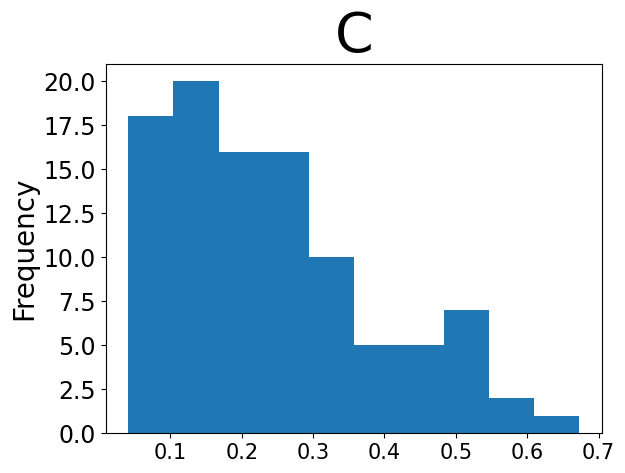

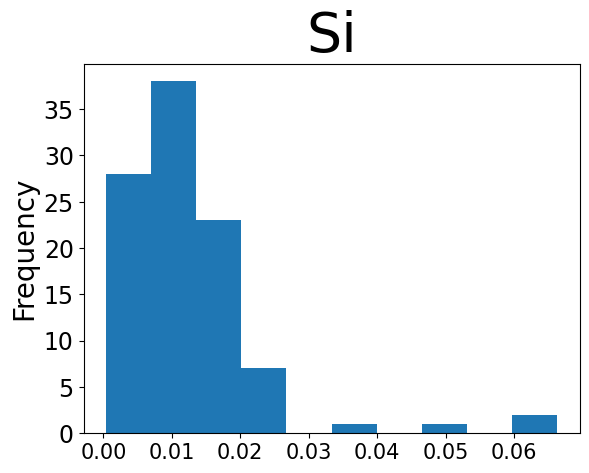

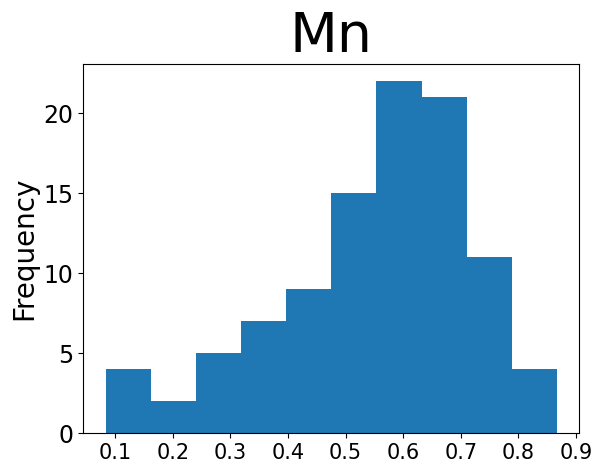

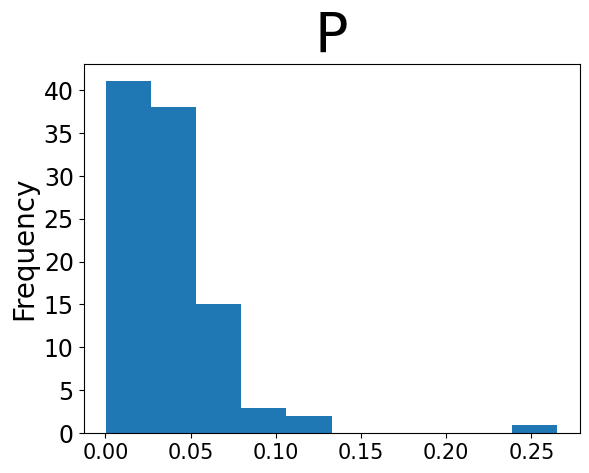

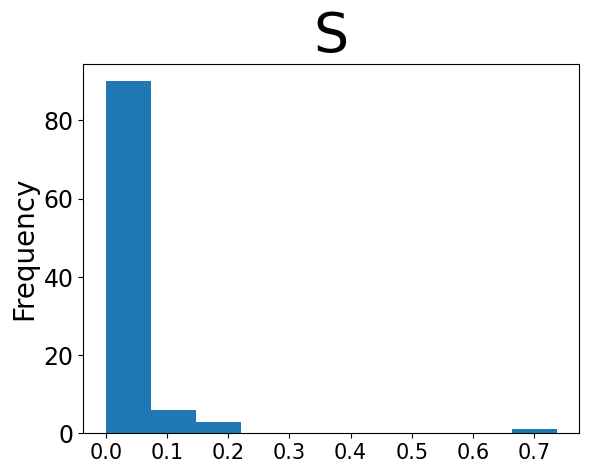

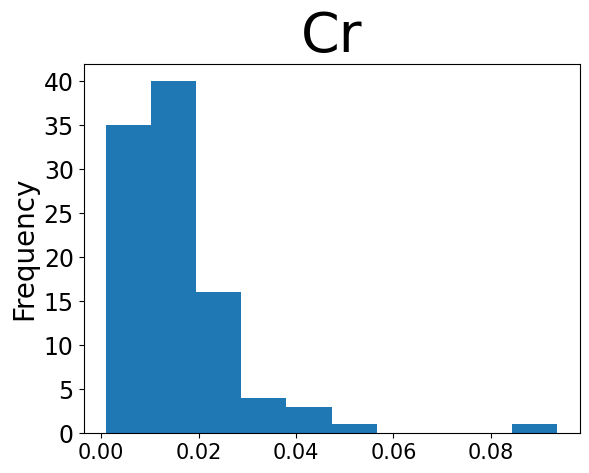

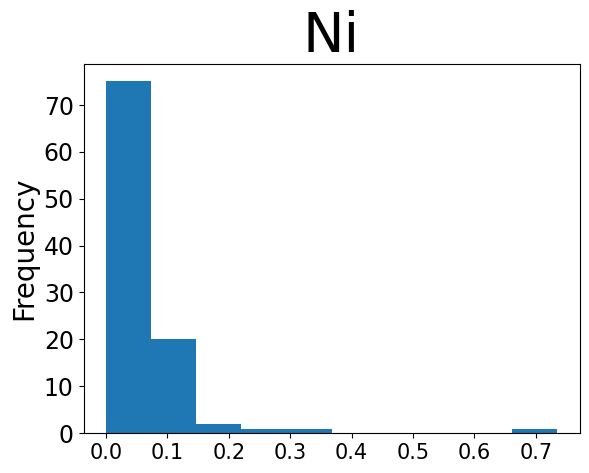

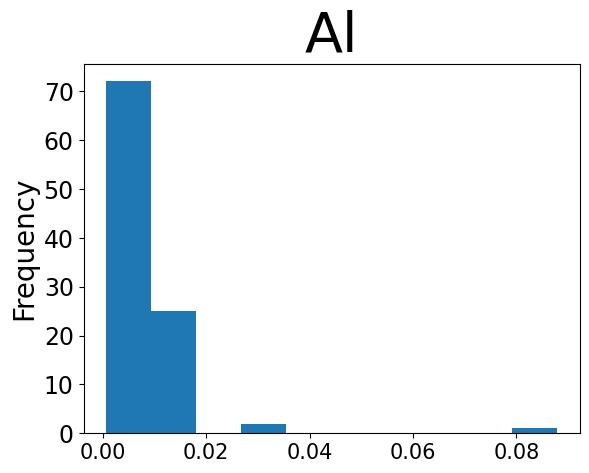

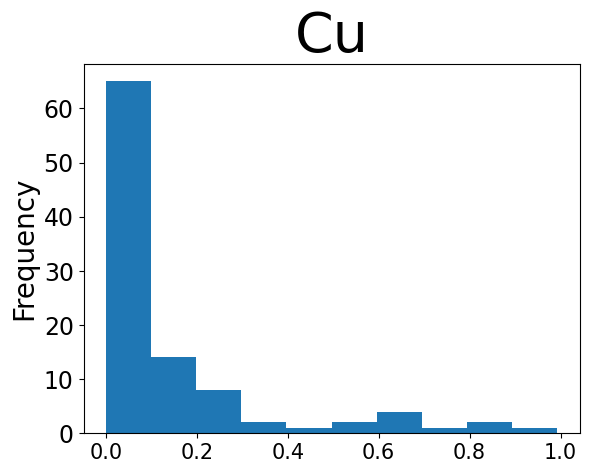

In [41]:
for col in df.columns:  # Loop through columns (excluding the first)
    df[col].plot.hist()
    plt.title(col, fontsize=40)  # Set title as element name
    plt.ylabel("Frequency", fontsize=20)
    plt.xticks(fontsize=15)  # Adjust x-axis tick label font size
    plt.yticks(fontsize=17)
    #plt.savefig(f"WGAN_Distribution_augmented_{col}.png", format='png')
    plt.show()
    plt.close()

<br>

## 7. Evaluate the quality of data with Steel Classification Neural Network

In [9]:
steel_classification_NN = keras.models.load_model("Steel_classifiying_Neural_Network.keras")

C:\Users\jonat\PycharmProjects\GAN_BA\venv\lib\site-packages\keras\src\saving\saving_lib.py:418: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 12 variables whereas the saved optimizer has 22 variables. 
  trackable.load_own_variables(weights_store.get(inner_path))


100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
100


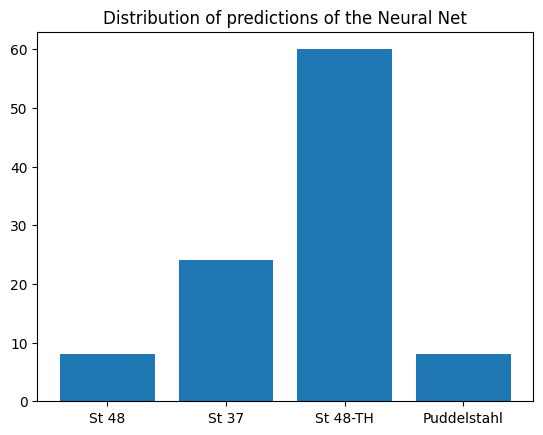

In [12]:
print(len(augmented_data_St48_TH))
predictions_aug_St48_TH = steel_classification_NN.predict(augmented_data_St48_TH)
rev_classes_dict = {0: "St 48", 1 : "St 37", 2 : "St Si", 3 : "St 48-TH", 4 : "Puddelstahl"}

df_NN = df.copy()

St_37 = 0
St_48_TH = 0
Puddelstahl = 0
St_48 = 0
counter = 0
for index, pred in enumerate(predictions_aug_St48_TH.argmax(axis=-1)):
    if rev_classes_dict[pred] == "St 37":
        St_37 += 1
        if St_37 >= 10:
            df_NN.drop(index, inplace=True)
    elif rev_classes_dict[pred] == "St 48-TH":
        St_48_TH += 1
    elif rev_classes_dict[pred] == "Puddelstahl":
        Puddelstahl += 1
        df_NN.drop(index, inplace=True)
    elif rev_classes_dict[pred] == "St 48":
        St_48 += 1
        if St_48 >= 10:
            df_NN.drop(index, inplace=True)
    counter += 1

print(counter)
classes = ["St 48", "St 37", "St 48-TH", "Puddelstahl"]
plt.bar(classes, [St_48, St_37, St_48_TH, Puddelstahl], align="center")
plt.title("Distribution of predictions of the Neural Net")  # Set title as element name

#plt.savefig('WGAN_NN_prediction_distribution.png', format='png')
#df_NN.to_csv("WGAN_Augmented_St48_TH_NN.csv", index=False)

In [44]:
predictions_aug_St48_TH.max(axis=-1)

array([0.6438223 , 0.9998362 , 0.9859714 , 0.9996517 , 0.73449826,
       0.3859203 , 0.91660726, 0.94129527, 0.88759625, 0.7969619 ,
       0.7346736 , 0.7406302 , 0.999154  , 0.7876189 , 1.        ,
       0.799852  , 0.9565642 , 0.70984125, 0.84060735, 0.7942877 ,
       0.82360834, 0.71123385, 0.5377241 , 0.9982527 , 0.7357829 ,
       0.9128059 , 0.9613646 , 0.988704  , 0.7883596 , 0.77306265,
       0.77597654, 0.94288117, 0.657298  , 1.        , 0.6703492 ,
       0.99770796, 0.72496825, 0.99965596, 0.9999999 , 0.8618557 ,
       0.9972156 , 0.99627125, 0.5688713 , 0.9448878 , 0.88786465,
       0.9847025 , 0.76887786, 0.9350213 , 0.991559  , 0.53327245,
       0.7812386 , 0.9966844 , 0.8538552 , 0.6081843 , 0.9541029 ,
       0.9481289 , 0.62968326, 0.79372346, 0.9998317 , 0.7654742 ,
       1.        , 0.9439244 , 0.997118  , 0.9591545 , 0.9754946 ,
       0.9999869 , 0.7571549 , 0.9911959 , 0.9896763 , 0.998803  ,
       0.976403  , 0.9944108 , 0.897093  , 0.9669189 , 0.47472

<br>

<br>

## 8. Evaluate the quality of data with Steel Classification XGBoost Classifier

In [13]:
steel_classifification_XGBoost = xgb.Booster()
steel_classifification_XGBoost.load_model("Steel_classifying_XGBoost.json")

In [16]:
df = pd.DataFrame(augmented_data_St48_TH, columns=["C", "Si", "Mn", "P", "S", "Cr", "Ni", "Al", "Cu"])
predictions_XGBoost = steel_classifification_XGBoost.predict(xgb.DMatrix(df))

for pred in predictions_XGBoost:
    print(rev_classes_dict[pred])

St 48-TH
St 48-TH
St 48-TH
St 48-TH
St 48-TH
St 48-TH
St 48-TH
St 48-TH
St 48-TH
St 48-TH
St 48-TH
St 48-TH
St 37
Puddelstahl
St 48-TH
St 37
St 48-TH
St 48-TH
St 37
St 48-TH
St 48-TH
St 48-TH
St 48-TH
St 48-TH
St 48-TH
St 48-TH
St 37
St 48-TH
St 37
St 48-TH
St 37
St 37
St 37
St 48-TH
St 48-TH
St 48-TH
St 48-TH
St 48-TH
St 48-TH
St 48-TH
St 37
St 48-TH
St 48-TH
Puddelstahl
St 48-TH
St 37
St 48-TH
St 48-TH
St 48-TH
St 48-TH
St 37
St 37
St 48-TH
St 37
St 48-TH
St 37
St 37
St 37
St 48-TH
St 37
St 48-TH
St 37
Puddelstahl
St 37
St 48-TH
St 48-TH
St 48-TH
St 37
St 48-TH
St 48-TH
St 48-TH
St 48-TH
St 48-TH
St 48-TH
St 37
St 48-TH
St 48-TH
St 37
St 48-TH
St 48-TH
St 48-TH
St 48-TH
St 48-TH
St 37
St 48-TH
St 37
St 48-TH
St 48-TH
St 48-TH
St 48-TH
St 48-TH
St 48-TH
St 48-TH
St 37
St 37
St 48-TH
St 37
St 48-TH
St 48-TH
Puddelstahl


100
(100, 9) (78, 9) (77, 9)


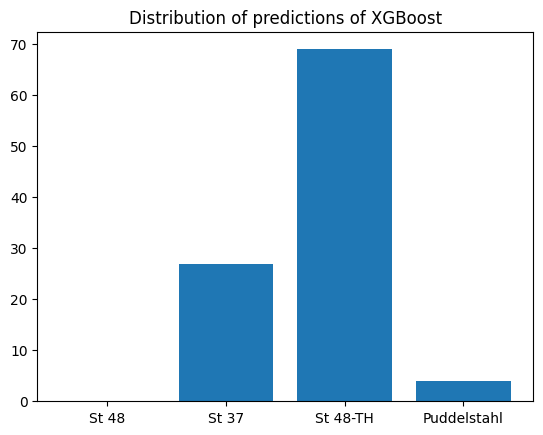

In [17]:
df_XGB = df.copy()
St_37 = 0
St_48_TH = 0
Puddelstahl = 0
St_48 = 0
counter = 0
for index, pred in enumerate(predictions_XGBoost):
    if rev_classes_dict[pred] == "St 37":
        St_37 += 1
        if St_37 >= 10:
            df_XGB.drop(index, inplace=True)
    elif rev_classes_dict[pred] == "St 48-TH":
        St_48_TH += 1
    elif rev_classes_dict[pred] == "Puddelstahl":
        Puddelstahl += 1
        df_XGB.drop(index, inplace=True)
    elif rev_classes_dict[pred] == "St 48":
        St_48 += 1
        if St_48 >= 10:
            df_XGB.drop(index, inplace=True)
    counter += 1

print(counter)
classes = ["St 48", "St 37", "St 48-TH", "Puddelstahl"]
plt.bar(classes, [St_48, St_37, St_48_TH, Puddelstahl], align="center")
plt.title("Distribution of predictions of XGBoost")  # Set title as element name

#plt.savefig('WGAN_XGB_prediction_distribution.png', format='png')
print(df.shape, df_XGB.shape, df_NN.shape)
df_XGB.to_csv("WGAN_Augmented_St48_TH_XGB.csv", index=False)